# 04 — Membersihkan teks buku

Saya membersihkan karakter HTML, spasi berulang, dan karakter kontrol dari judul, abstrak, serta kategori. Stopword dan stemming tidak diterapkan secara menyeluruh karena kebutuhan model leksikal dan transformer berbeda. Data mentah tetap disimpan tanpa perubahan.

## 1. Persiapan data

In [1]:
from pathlib import Path
import re, html, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset_buku_2000.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'dataset_buku_2000.csv').exists(), 'Buka folder utama proyek atau notebook dari subfolder notebooks.'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
books = pd.read_csv(DATA / 'dataset_buku_2000.csv', dtype=str).fillna('')
comps = pd.read_csv(DATA / 'competencies_green.csv', dtype=str).fillna('')
print(f'Buku: {len(books):,} | Kompetensi: {len(comps)}')

Buku: 973 | Kompetensi: 67


## 2. Membuat fungsi pembersihan yang dapat diuji

In [2]:
def bersihkan(teks):
    teks = html.unescape(str(teks))
    teks = re.sub(r'<[^>]+>', ' ', teks)
    teks = re.sub(r'[\x00-\x1f\x7f]', ' ', teks)
    return re.sub(r'\s+', ' ', teks).strip()

contoh='<p>Risk &amp; Financial <b>Management</b>  </p>'
print('Sebelum:',contoh)
print('Sesudah:',bersihkan(contoh))
assert bersihkan(contoh)=='Risk & Financial Management'

Sebelum: <p>Risk &amp; Financial <b>Management</b>  </p>
Sesudah: Risk & Financial Management


## 3. Terapkan fungsi tanpa mengganti data mentah

In [3]:
clean=books.copy()
for kolom in ['judul','abstrak','kategori_buku','author']:
    clean[kolom+'_bersih']=clean[kolom].map(bersihkan)
clean['teks_model']=(clean['judul_bersih']+' '+clean['judul_bersih']+' '+clean['abstrak_bersih']+' '+clean['kategori_buku_bersih']).str.strip()
clean['teks_buku']=clean['teks_model']
# Kolom kompetensi historis tetap ada hanya untuk audit, bukan untuk pencocokan.
display(clean[['judul','judul_bersih','abstrak_bersih','teks_model']].head(3).T)

,0,1,2
judul,Business Growth Strategy,Mastering Business Growth Strategies,AI-Powered Business Growth Strategies
judul_bersih,Business Growth Strategy,Mastering Business Growth Strategies,AI-Powered Business Growth Strategies
abstrak_bersih,"Introduction I wrote this book, “Business Grow...",Mastering Business Growth Strategies: Gaining ...,AI-Powered Business Growth Strategies is a pra...
teks_model,Business Growth Strategy Business Growth Strat...,Mastering Business Growth Strategies Mastering...,AI-Powered Business Growth Strategies AI-Power...


## 4. Tampilkan perubahan sebelum dan sesudah

In [4]:
contoh_perbandingan=pd.DataFrame({'book_id':clean.book_id.head(5),
 'teks_awal':books.abstrak.head(5).str.slice(0,150),
 'teks_bersih':clean.abstrak_bersih.head(5).str.slice(0,150)})
display(contoh_perbandingan)

,book_id,teks_awal,teks_bersih
0,BK00001,"Introduction I wrote this book, “Business Grow...","Introduction I wrote this book, “Business Grow..."
1,BK00002,Mastering Business Growth Strategies: Gaining ...,Mastering Business Growth Strategies: Gaining ...
2,BK00003,AI-Powered Business Growth Strategies is a pra...,AI-Powered Business Growth Strategies is a pra...
3,BK00004,The majority of family businesses are both ill...,The majority of family businesses are both ill...
4,BK00005,Seminar paper from the year 2016 in the subjec...,Seminar paper from the year 2016 in the subjec...


## 5. Audit panjang teks model

count     973.0
mean      162.7
std       123.1
min        19.0
25%        73.0
50%       144.0
75%       220.0
max      2124.0
Name: teks_model, dtype: float64


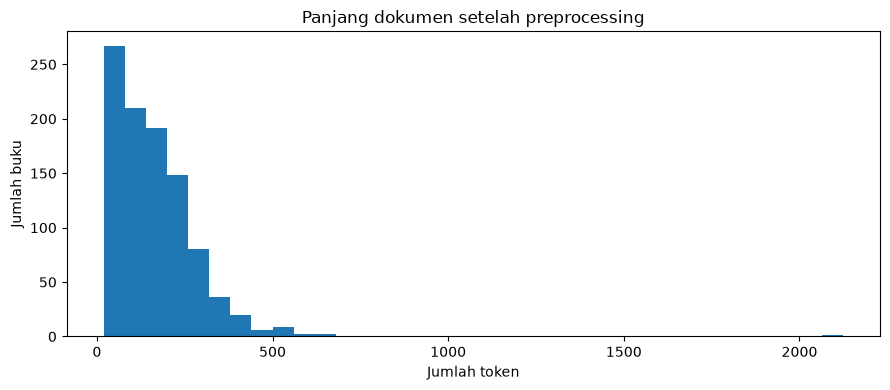

In [5]:
panjang = clean['teks_model'].str.split().map(len)
print(panjang.describe().round(1))
fig,ax=plt.subplots(figsize=(9,4));ax.hist(panjang,bins=35)
ax.set(title='Panjang dokumen setelah preprocessing',xlabel='Jumlah token',ylabel='Jumlah buku')
plt.tight_layout();plt.savefig(FIG/'04_panjang_teks_bersih.png',dpi=160);plt.show()

## 6. Pemeriksaan dan penyimpanan

In [6]:
assert len(clean)==len(books)
assert clean.book_id.is_unique
assert set(clean.book_id)==set(books.book_id)
clean.to_csv(OUT/'dataset_buku_bersih.csv',index=False,encoding='utf-8-sig')
print('Dataset bersih tersimpan:',OUT/'dataset_buku_bersih.csv')
print('Baris dengan teks kosong:',int(clean.teks_model.eq('').sum()))

Dataset bersih tersimpan: c:\Users\AUREL ELVIOLITA\Downloads\BPJS_Book_Recommendation\Book_Recommendation\outputs\dataset_buku_bersih.csv
Baris dengan teks kosong: 0


## Kesimpulan tahap
Teks telah dibersihkan dan dipersiapkan menjadi input bersama. Tahap selanjutnya menyusun profil kompetensi yang menjadi query model, tanpa memakai label historis buku sebagai jawaban benar.